In [5]:
# Step 1: Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import confusion_matrix, classification_report

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, RepeatVector, TimeDistributed, Dense

In [6]:
# Step 2: Load the NASA Turbofan Engine Dataset
data = pd.read_csv("NASA TurboFan Engine.csv")

# Sort data by engine ID and operating cycle
data = data.sort_values(["unit", "cycle"])

# Select the 21 sensor columns
sensor_columns = [f"sensor{i}" for i in range(1, 22)]

# Store fault labels separately for evaluation
labels = data["Fault_Label"].values

In [7]:
# Step 3: Preprocess and scale the sensor readings
# Fill missing sensor values, if any
data[sensor_columns] = data[sensor_columns].ffill().bfill()

# Select healthy sensor readings for training
normal_data = data[data["Fault_Label"] == 0].copy()

# Normalize sensor readings between 0 and 1
scaler = MinMaxScaler()

scaler.fit(normal_data[sensor_columns])

data[sensor_columns] = scaler.transform(data[sensor_columns])

# Update normal data with scaled sensor readings
normal_data = data[data["Fault_Label"] == 0].copy()


In [8]:
# Step 4: Create time windows for sequential input
# Each window contains 20 consecutive sensor readings.
# Windows are created separately for each engine.

window_size = 20

def create_windows(values, window_size):
    windows = []

    for i in range(len(values) - window_size + 1):
        windows.append(values[i:i + window_size])

    return np.array(windows)


# Create windows from normal data for training
X_train_list = []

for engine_id, engine_data in normal_data.groupby("unit"):

    engine_data = engine_data.sort_values("cycle")

    values = engine_data[sensor_columns].values

    windows = create_windows(values, window_size)

    if len(windows) > 0:
        X_train_list.append(windows)

X_train = np.concatenate(X_train_list, axis=0)

print("Training data shape:", X_train.shape)

Training data shape: (15631, 20, 21)


In [9]:
# Step 5: Create test windows from all engine data
# Store the label for each window.
# A window is faulty if any reading in it has Fault_Label = 1.

X_test_list = []
y_test_list = []

for engine_id, engine_data in data.groupby("unit"):

    engine_data = engine_data.sort_values("cycle")

    values = engine_data[sensor_columns].values
    engine_labels = engine_data["Fault_Label"].values

    windows = create_windows(values, window_size)

    # Create one label for each window
    window_labels = []

    for i in range(len(engine_labels) - window_size + 1):
        label = np.max(engine_labels[i:i + window_size])
        window_labels.append(label)

    if len(windows) > 0:
        X_test_list.append(windows)
        y_test_list.append(np.array(window_labels))

X_test = np.concatenate(X_test_list, axis=0)
y_test = np.concatenate(y_test_list, axis=0)

print("Testing data shape:", X_test.shape)

Testing data shape: (18731, 20, 21)


In [10]:
# Step 6: Build an LSTM-based Autoencoder
# Encoder learns normal sensor patterns.
# Decoder reconstructs the original sensor sequence.

input_layer = Input(shape=(window_size, len(sensor_columns)))

# Encode the sensor sequence
encoded = LSTM(64, activation="relu")(input_layer)

# Repeat the encoded representation for all time steps
decoded = RepeatVector(window_size)(encoded)

# Decode the sequence
decoded = LSTM(
    64,
    activation="relu",
    return_sequences=True
)(decoded)

# Reconstruct all 21 sensor values
decoded = TimeDistributed(
    Dense(len(sensor_columns))
)(decoded)

# Create the autoencoder model
autoencoder = Model(input_layer, decoded)

autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 20, 21)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ (None, 64)                  │          22,016 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ repeat_vector (RepeatVector)         │ (None, 20, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 20, 64)              │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed (TimeDistributed)   │ (None, 20, 21)              │           1,365 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 56,405 (220.33 KB)

 Trainable params: 56,405 (220.33 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# Step 7: Compile the model
# Adam optimizer and Mean Squared Error loss
autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

In [12]:
# Step 8: Train the model on normal sensor data
# Input and target are the same for an autoencoder.

history = autoencoder.fit(
    X_train,
    X_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    shuffle=False
)


Epoch 1/20
440/440 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - loss: 0.0177 - val_loss: 0.0068
Epoch 2/20
440/440 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - loss: 0.0065 - val_loss: 0.0059
Epoch 3/20
440/440 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - loss: 0.0060 - val_loss: 0.0057
Epoch 4/20
440/440 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - loss: 0.0058 - val_loss: 0.0057
Epoch 5/20
440/440 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - loss: 0.0058 - val_loss: 0.0057
Epoch 6/20
440/440 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - loss: 0.0058 - val_loss: 0.0056
Epoch 7/20
440/440 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - loss: 0.0058 - val_loss: 0.0056
Epoch 8/20
440/440 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - loss: 0.0057 - val_loss: 0.0056
Epoch 9/20
440/440 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - loss: 0.0058 - val_loss: 0.0056
Epoch 10/20
440/440 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - loss: 0.0057 - val_loss: 0.0055
Epoch 11/20
440/440 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - loss: 0.0057 - val_loss: 0.0055
Epoch 12/20
440/440 ━━━━━━━━━━━━━━━

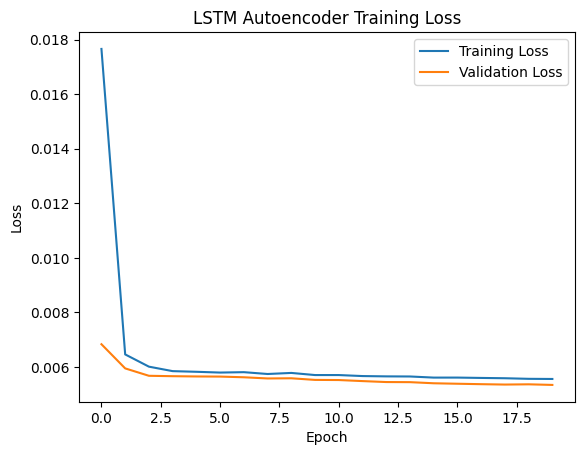

In [13]:
# Step 9: Plot training and validation loss
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM Autoencoder Training Loss")

plt.legend()
plt.show()


In [14]:
# Step 10: Reconstruct the testing sensor data
reconstructed = autoencoder.predict(X_test)

586/586 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step


In [15]:
# Step 11: Calculate reconstruction error
# Higher error means the pattern differs from normal data.

errors = np.mean(
    np.square(X_test - reconstructed),
    axis=(1, 2)
)

In [16]:
# Step 12: Set an error threshold
# Use the 95th percentile of normal training errors.

train_reconstructed = autoencoder.predict(X_train)

train_errors = np.mean(
    np.square(X_train - train_reconstructed),
    axis=(1, 2)
)

threshold = np.percentile(train_errors, 95)

print("Fault detection threshold:", threshold)

489/489 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step
Fault detection threshold: 0.009552096725557076


In [17]:
# Step 13: Detect faults using reconstruction error
# Error greater than threshold means a possible fault.

predictions = (errors > threshold).astype(int)

print("Possible faulty windows:", np.sum(predictions))

Possible faulty windows: 951


In [18]:
# Step 13: Detect faults using reconstruction error
# Error greater than threshold means a possible fault.

predictions = (errors > threshold).astype(int)

print("Possible faulty windows:", np.sum(predictions))

Possible faulty windows: 951


In [19]:
# Step 14: Evaluate detected faults using the provided labels
# Fault_Label is used only to evaluate the result.

print("Confusion Matrix:")
print(confusion_matrix(y_test, predictions))

print("Classification Report:")
print(classification_report(y_test, predictions))

Confusion Matrix:
[[14849   782]
 [ 2931   169]]
Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.95      0.89     15631
           1       0.18      0.05      0.08      3100

    accuracy                           0.80     18731
   macro avg       0.51      0.50      0.49     18731
weighted avg       0.73      0.80      0.76     18731



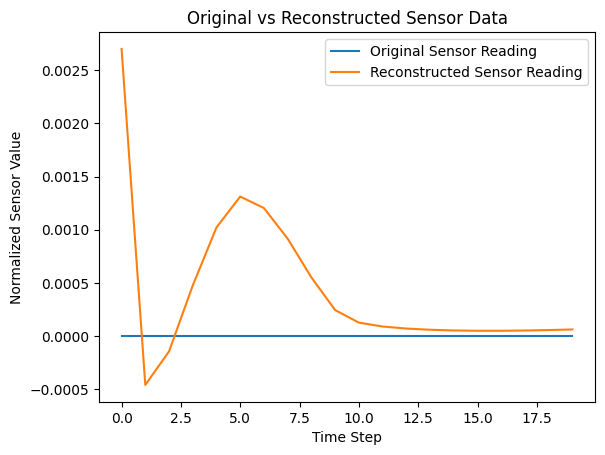

In [20]:
# Step 15: Visualize original and reconstructed sensor readings
# Plot sensor 1 for one test window.

i = 0

plt.plot(
    X_test[i, :, 0],
    label="Original Sensor Reading"
)

plt.plot(
    reconstructed[i, :, 0],
    label="Reconstructed Sensor Reading"
)

plt.xlabel("Time Step")
plt.ylabel("Normalized Sensor Value")
plt.title("Original vs Reconstructed Sensor Data")

plt.legend()
plt.show()


In [21]:
# Step 16: Display the fault detection result
print("Reconstruction Error:", errors[i])

if predictions[i] == 1:
    print("Possible Engine Fault Detected")
else:
    print("Normal Engine Pattern")

Reconstruction Error: 0.004699462463929381
Normal Engine Pattern
